In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
np.random.seed(42)


In [12]:

import pandas as pd
from pathlib import Path

# Dataset folder
DATA_DIR = Path("../data/airline_clustering")

# Load CSV files
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)

# Combine both datasets
df = pd.concat([train, test], ignore_index=True)

# Remove ID columns if present
df.drop(columns=["Unnamed: 0", "id"], errors="ignore", inplace=True)

print("Combined shape:", df.shape)
display(df.head())


Train shape: (103904, 25)
Test shape: (25976, 25)
Combined shape: (129880, 23)


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [13]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

if "satisfaction" in df.columns:
    print("\nPassenger satisfaction counts:")
    print(df["satisfaction"].value_counts())


Dataset shape: (129880, 23)

Column names:
['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']

Data types:


,Data Type
Gender,str
Customer Type,str
Age,int64
Type of Travel,str
Class,str
Flight Distance,int64
Inflight wifi service,int64
Departure/Arrival time convenient,int64
Ease of Online booking,int64
Gate location,int64



Missing values:


,Missing Values
Gender,0
Customer Type,0
Age,0
Type of Travel,0
Class,0
Flight Distance,0
Inflight wifi service,0
Departure/Arrival time convenient,0
Ease of Online booking,0
Gate location,0



Duplicate rows: 0

Passenger satisfaction counts:
satisfaction
neutral or dissatisfied    73452
satisfied                  56428
Name: count, dtype: int64


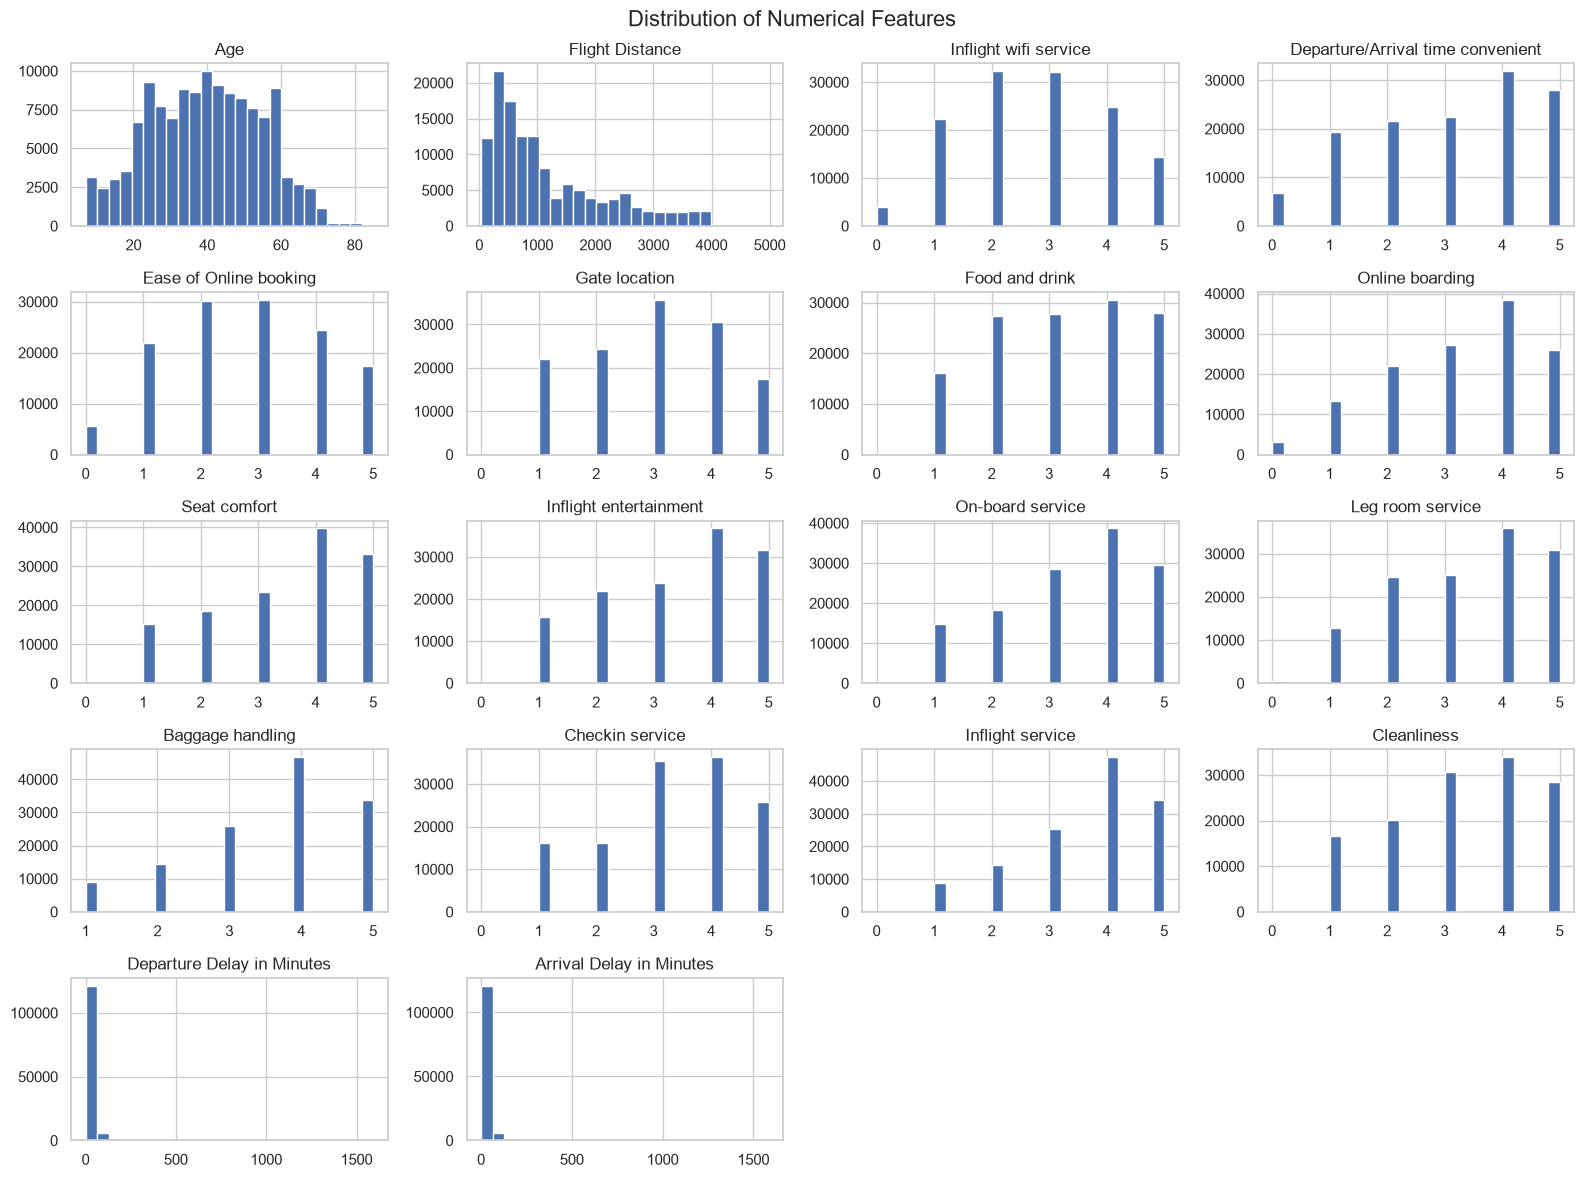

In [15]:
# Select columns containing numerical data
numeric_cols = df.select_dtypes(include=np.number).columns

# Plot histograms to understand numerical feature distributions
df[numeric_cols].hist(figsize=(16, 12), bins=25)

# Add a title to the overall figure
plt.suptitle("Distribution of Numerical Features", fontsize=16)

# Adjust spacing to prevent overlapping plots
plt.tight_layout()

# Display the histograms
plt.show()

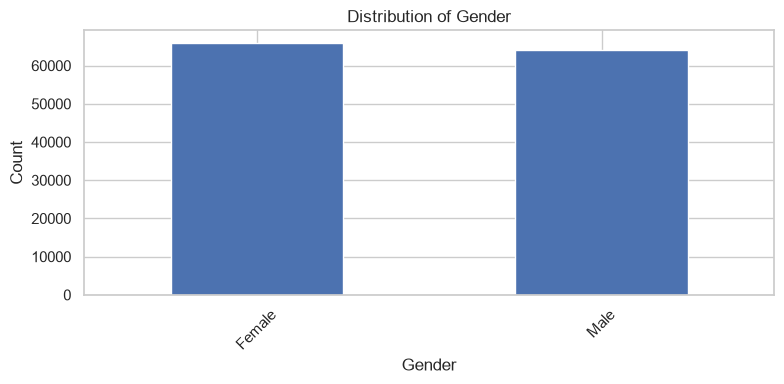

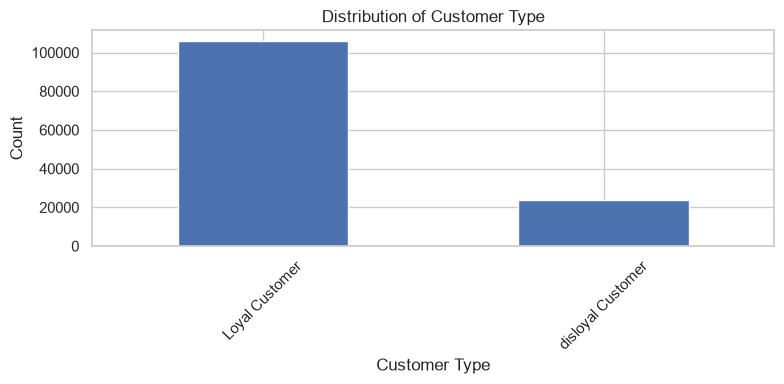

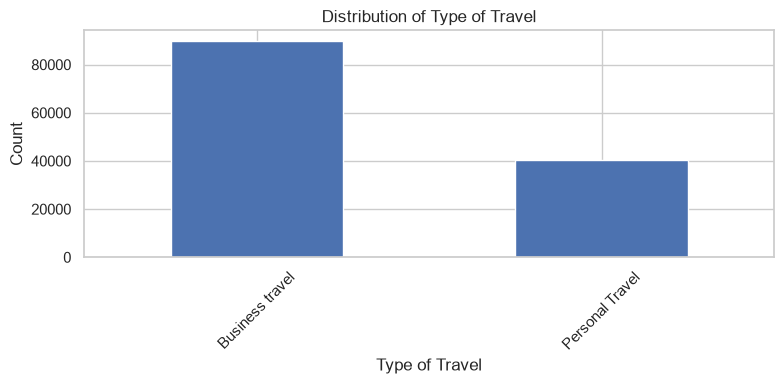

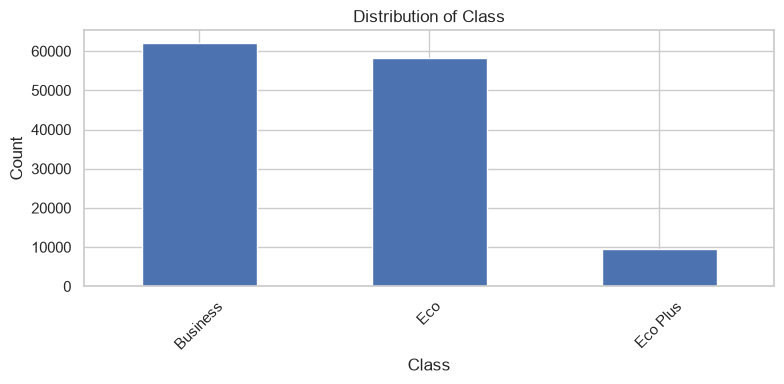

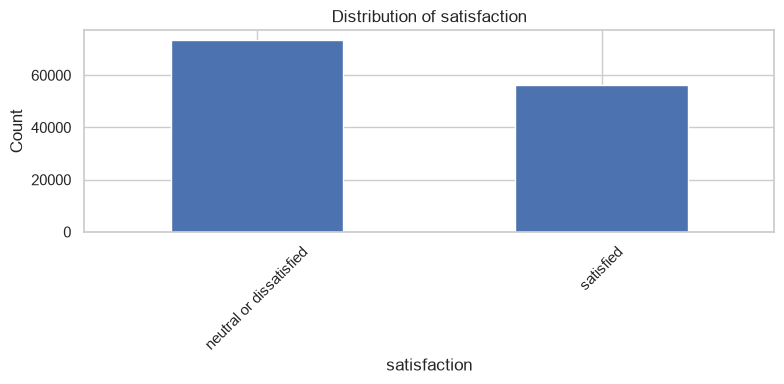

In [16]:
# Select columns containing categorical data
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

# Plot a bar chart for each categorical column
for col in categorical_cols:

    # Create a new figure
    plt.figure(figsize=(8, 4))

    # Count each category and plot the most common 15
    df[col].value_counts().head(15).plot(kind="bar")

    # Add chart labels
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")

    # Rotate labels for readability
    plt.xticks(rotation=45)

    # Adjust the chart layout
    plt.tight_layout()

    # Display the chart
    plt.show()